# H2 benchmark: EfficientSU2, UCCSD and fUCCSD with ZNE and CDR

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

## Setup

In [2]:
import contextlib
import io
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from pyscf import mcscf
from qiskit.circuit.library import efficient_su2
from qiskit.primitives import StatevectorSampler
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.operators import FermionicOp
from slowquant.qiskit_interface.circuit_wavefunction import WaveFunctionCircuit
from slowquant.qiskit_interface.interface import QuantumInterface

from src.utils import load_config
from src.chem import get_molecule, get_problem, get_ansatz
from src.backend import run_vqe, get_transpiled
from src.mitigation import ZNE, CDR

load_config("configs/lih.yaml")

molecule, mf, cas = get_molecule()
problem = get_problem()
e_nuc = molecule.energy_nuc()
mapper = JordanWignerMapper()

E_hf = mf.e_tot
E_fci = mcscf.CASCI(mf, cas[1], cas[0]).run().e_tot
print(f"HF  : {E_hf:.6f} Ha")
print(f"FCI : {E_fci:.6f} Ha")

HF  : -7.862024 Ha
FCI : -7.863219 Ha


## Ansatze

Each ansatz comes with its own Hamiltonian:

- **EfficientSU2, UCCSD** use the Qiskit Nature Hamiltonian.
- **fUCCSD** uses the Hamiltonian from SlowQuant's wavefunction, so it matches SlowQuant's orbitals.

UCCSD and fUCCSD start from θ = 0 (the HF state). EfficientSU2 starts from small random values, because θ = 0 is not the HF state for it.

In [3]:
ANSATZE = ["EfficientSU2", "UCCSD", "fUCCSD"]
results = {name: {} for name in ANSATZE}

## VQE (noiseless) and transpiling

In [4]:
for name in ANSATZE:
    ansatz, hamiltonian, x0 = get_ansatz(name)
    vqe_energy, theta_opt = run_vqe(ansatz, hamiltonian, x0)
    transpiled_ansatz, transpiled_hamiltonian = get_transpiled(ansatz, theta_opt, hamiltonian)

    results[name].update(
        ansatz=ansatz,
        hamiltonian=hamiltonian,
        theta_opt=theta_opt,
        transpiled_ansatz=transpiled_ansatz,
        transpiled_hamiltonian=transpiled_hamiltonian,
        E_exact=vqe_energy + e_nuc,
    )
    print(f"{name:13s} params = {ansatz.num_parameters:3d}   "
          f"E_VQE = {vqe_energy + e_nuc:.6f} Ha   "
          f"error vs FCI = {abs(vqe_energy + e_nuc - E_fci):.2e} Ha   "
          f"transpiled depth = {transpiled_ansatz.depth()}")

EfficientSU2  params =  32   E_VQE = -7.862018 Ha   error vs FCI = 1.20e-03 Ha   transpiled depth = 28


/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/env/lib/python3.11/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/Users/azadtoukiribn/QIS/Thesis/qem-chem-benchmark/env/lib/python3.11/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


UCCSD         params =  26   E_VQE = -7.863219 Ha   error vs FCI = 5.95e-07 Ha   transpiled depth = 2187
fUCCSD        params =  26   E_VQE = -7.863219 Ha   error vs FCI = 4.25e-07 Ha   transpiled depth = 848


## ZNE

In [5]:
date = datetime.now().strftime("%Y-%m-%d")

for name in ANSATZE:
    r = results[name]
    zne = ZNE()
    zne.run(r["transpiled_ansatz"], r["transpiled_hamiltonian"], e_nuc)
    zne.save(f"data/LiH_{name}_ZNE_{date}.npz")
    r["zne"] = zne
    r["E_noisy"] = zne.energies[0]
    print(f"{name:13s} energies at λ = {zne.lambdas}: {np.round(zne.energies, 6)}")

EfficientSU2  energies at λ = [1. 3. 5. 7. 9.]: [-7.816299 -7.733532 -7.65392  -7.577315 -7.503581]
UCCSD         energies at λ = [1. 3. 5. 7. 9.]: [-6.312632 -5.652329 -5.372964 -5.19571  -5.079269]
fUCCSD        energies at λ = [1. 3. 5. 7. 9.]: [-5.461042 -4.891479 -4.882848 -4.887837 -4.88994 ]


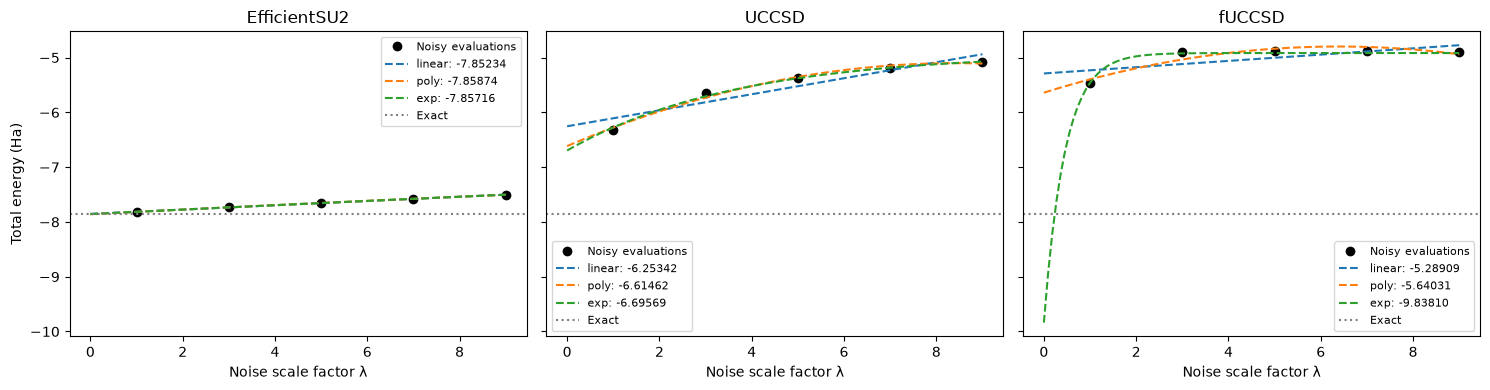

In [6]:
fig, axes = plt.subplots(1, len(ANSATZE), figsize=(5 * len(ANSATZE), 4), sharey=True)
x = np.linspace(0, max(ZNE().noise_factors), 100)

for ax, name in zip(axes, ANSATZE):
    r = results[name]
    zne = r["zne"]
    ax.plot(zne.lambdas, zne.energies, "ko", label="Noisy evaluations")
    for method in ["linear", "poly", "exp"]:
        E0, curve = zne.extrapolate(method)
        ax.plot(x, [curve(xi) for xi in x], "--", label=f"{method}: {E0:.5f}")
    ax.axhline(r["E_exact"], color="gray", ls=":", label="Exact")
    ax.set_title(name)
    ax.set_xlabel("Noise scale factor λ")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Total energy (Ha)")
plt.tight_layout()
plt.show()

Choose the extrapolation for each ansatz from the plots:

In [26]:
zne_method = {
    "EfficientSU2": "linear",
    "UCCSD": "poly",
    "fUCCSD": "exp",
}

for name in ANSATZE:
    r = results[name]
    r["E_zne"], _ = r["zne"].extrapolate(zne_method[name])
    print(f"{name:13s} ({zne_method[name]:6s})  Noisy error = {abs(r['E_noisy'] - r['E_exact']):.6f}  | "
          f"ZNE mit Energy : {r['E_zne']} Ha | "
          f"ZNE error = {abs(r['E_zne'] - r['E_exact']):.6f} Ha")

EfficientSU2  (linear)  Noisy error = 0.045718  | ZNE mit Energy : -7.852342892150111 Ha | ZNE error = 0.009675 Ha
UCCSD         (poly  )  Noisy error = 1.550587  | ZNE mit Energy : -6.614617515314887 Ha | ZNE error = 1.248601 Ha
fUCCSD        (exp   )  Noisy error = 2.402177  | ZNE mit Energy : -9.838097194568531 Ha | ZNE error = 1.974878 Ha


## CDR 

In [ ]:
for name in ANSATZE:
    r = results[name]
    cdr = CDR()
    print(f"{name}: ", end="")
    circuits = cdr.training_circuits(r["transpiled_ansatz"])
    cdr.training_data(circuits, r["hamiltonian"], e_nuc, True)
    cdr.save(f"data/LiH_{name}_CDR_{date}.npz")
    r["cdr"] = cdr

EfficientSU2: n = 39 non-Clifford gates, k = 1 -> C(n, k) = 39
UCCSD: n = 226 non-Clifford gates, k = 1 -> C(n, k) = 226
fUCCSD: n = 136 non-Clifford gates, k = 1 -> C(n, k) = 136


To skip the slow part later, load saved training data instead:

```python
cdr = CDR()
cdr.load("data/LiH_fUCCSD_CDR_<date>.npz")
results["fUCCSD"]["cdr"] = cdr
```

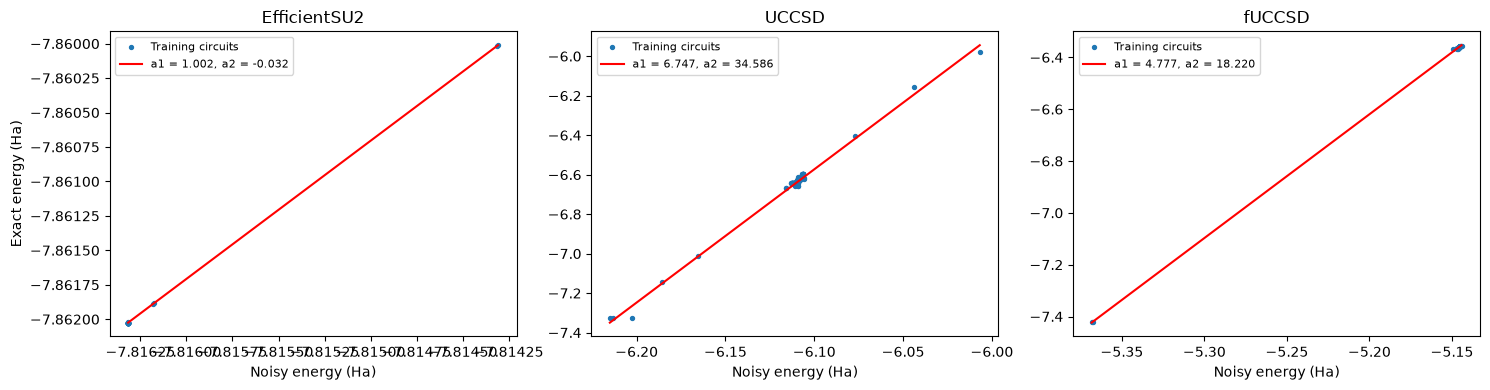

In [19]:
fig, axes = plt.subplots(1, len(ANSATZE), figsize=(5 * len(ANSATZE), 4))

for ax, name in zip(axes, ANSATZE):
    r = results[name]
    cdr = r["cdr"]
    a1, a2 = cdr.fit()
    r["E_cdr"] = float(cdr.mitigate(r["E_noisy"]))

    x = np.linspace(cdr.X_noisy.min(), cdr.X_noisy.max(), 100)
    ax.scatter(cdr.X_noisy, cdr.X_exact, s=8, label="Training circuits")
    ax.plot(x, cdr.mitigate(x), "r-", label=f"a1 = {a1:.3f}, a2 = {a2:.3f}")
    ax.set_title(name)
    ax.set_xlabel("Noisy energy (Ha)")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Exact energy (Ha)")
plt.tight_layout()
plt.show()

## Summary

In [17]:
print(f"{'Ansatz':13s} {'Exact':>11s} {'Noisy':>11s} {'ZNE':>11s} {'CDR':>11s}   "
      f"{'err Noisy':>10s} {'err ZNE':>10s} {'err CDR':>10s}")
for name in ANSATZE:
    r = results[name]
    errs = [abs(r[k] - r["E_exact"]) for k in ("E_noisy", "E_zne", "E_cdr")]
    print(f"{name:13s} {r['E_exact']:11.6f} {r['E_noisy']:11.6f} {r['E_zne']:11.6f} {r['E_cdr']:11.6f}   "
          + " ".join(f"{e:10.2e}" for e in errs))

Ansatz              Exact       Noisy         ZNE         CDR    err Noisy    err ZNE    err CDR
EfficientSU2    -7.862018   -7.816299   -7.852343   -7.862007     4.57e-02   9.67e-03   1.09e-05
UCCSD           -7.863219   -6.312632   -6.614618   -8.007760     1.55e+00   1.25e+00   1.45e-01
fUCCSD          -7.863219   -5.461042   -9.838097   -7.866547     2.40e+00   1.97e+00   3.33e-03


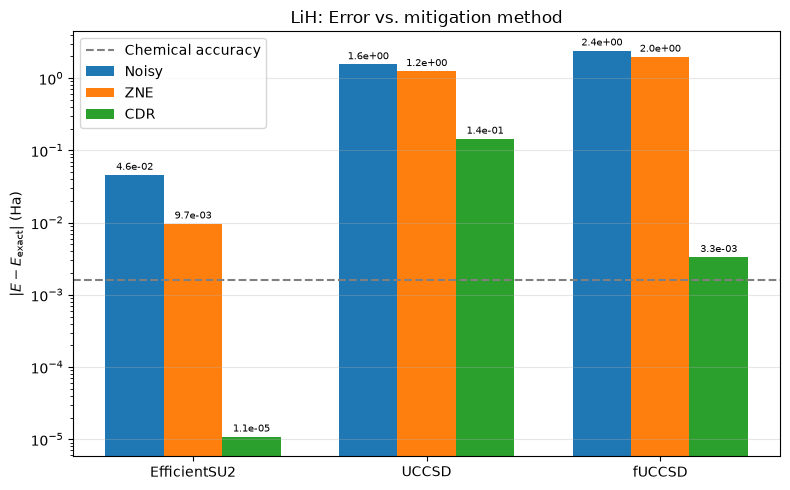

In [37]:
import numpy as np
import matplotlib.pyplot as plt

methods = [("E_noisy", "Noisy"), ("E_zne", "ZNE"), ("E_cdr", "CDR")]
x = np.arange(len(ANSATZE))
w = 0.25

fig, ax = plt.subplots(figsize=(8, 5))
for i, (key, label) in enumerate(methods):
    errs = [abs(results[n][key] - results[n]["E_exact"]) for n in ANSATZE]
    bars = ax.bar(x + (i - 1) * w, errs, w, label=label)
    ax.bar_label(bars, labels=[f"{e:.1e}" for e in errs], fontsize=7, padding=2)

plt.axhline(1.6e-3, color="gray", ls="--", label="Chemical accuracy")

ax.set_xticks(x)
ax.set_xticklabels(ANSATZE)
ax.set_ylabel(r"$|E - E_\mathrm{exact}|$ (Ha)")
ax.set_yscale("log")
ax.set_title("LiH: Error vs. mitigation method")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"plots/LiH_mitigation_errors_{date}.png", dpi=200)
plt.show()